<a href="https://colab.research.google.com/github/SaharaAli16/UNT_Teaching/blob/main/DTSC_4050/Week_11_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DTSC 4050 — Classification
## Python Class Activity Notebook



## Learning Objectives

By the end of this activity, you should be able to:

1. Identify a classification problem and determine whether it is binary.
2. Distinguish an observation, feature/attribute, class, training set, and classifier.
3. Calculate Euclidean distance between observations.
4. Explain why standardization is important for distance-based classification.
5. Implement 1-NN and k-NN classification.
6. Split labeled observations into training and test sets.
7. Calculate and interpret classification accuracy.
8. Identify false positives and false negatives.
9. Investigate how the choice of \(k\) affects predictions and test accuracy.
10. Use multiple attributes in a k-NN classifier.

## Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(4050)

# Part 1 — What Is Classification?

**Classification** predicts a categorical class or label.

Examples:

| Problem | Possible Classes |
|---|---|
| Fraud detection | Fraud / Not Fraud |
| Medical diagnosis | Disease / No Disease |
| Email filtering | Spam / Not Spam |
| Credit default | Default / No Default |

When there are exactly **two possible classes**, the problem is called **binary classification**.

# Part 2 — Key Classification Terminology

For this notebook:

- **Observation:** One individual or situation we want to classify.
- **Attribute / Feature:** A known measurement about an observation.
- **Class / Label:** The category we want to predict.
- **Training data:** Observations whose correct classes are already known.
- **Classifier:** An algorithm that predicts the class of a new observation.
- **Test data:** Labeled observations kept separate so we can evaluate the classifier.

# Part 3 — Create a CKD-Style Patient Dataset

Each row represents one patient.

We will use three attributes:

- Hemoglobin
- Glucose
- White Blood Cell Count (WBC)

The class is:

- `1` = CKD
- `0` = No CKD

> These data are synthetic and are used only for practicing classification concepts.

In [3]:
n_ckd = 80
n_no_ckd = 80

ckd = pd.DataFrame({
    "Hemoglobin": rng.normal(10.6, 1.4, n_ckd),
    "Glucose": rng.normal(155, 32, n_ckd),
    "WBC": rng.normal(8.5, 1.7, n_ckd),
    "Class": np.ones(n_ckd, dtype=int)
})

no_ckd = pd.DataFrame({
    "Hemoglobin": rng.normal(14.0, 1.2, n_no_ckd),
    "Glucose": rng.normal(103, 22, n_no_ckd),
    "WBC": rng.normal(6.8, 1.3, n_no_ckd),
    "Class": np.zeros(n_no_ckd, dtype=int)
})

patients = pd.concat([ckd, no_ckd], ignore_index=True)

patients.head()

,Hemoglobin,Glucose,WBC,Class
0,8.630900,183.927966,9.689613,1
1,10.024317,163.413853,5.904072,1
2,11.382577,148.034512,10.950465,1
3,12.782870,148.156932,9.944203,1
4,10.217016,203.317831,9.515625,1


### Examine the Dataset

In [4]:
print("Number of observations:", len(patients))
print()
print(patients["Class"].value_counts())
print()
patients.describe()

Number of observations: 160

Class
1    80
0    80
Name: count, dtype: int64



,Hemoglobin,Glucose,WBC,Class
count,160.000000,160.000000,160.000000,160.00000
mean,12.272329,128.403585,7.728478,0.50000
std,2.178129,38.518710,1.596610,0.50157
min,7.750025,28.876221,4.176757,0.00000
25%,10.434693,99.660935,6.705053,0.00000
50%,12.319077,120.696191,7.629586,0.50000
75%,14.132517,163.164582,9.006947,1.00000
max,17.428625,244.890021,11.693222,1.00000


# Part 4 — Visualizing the Classes

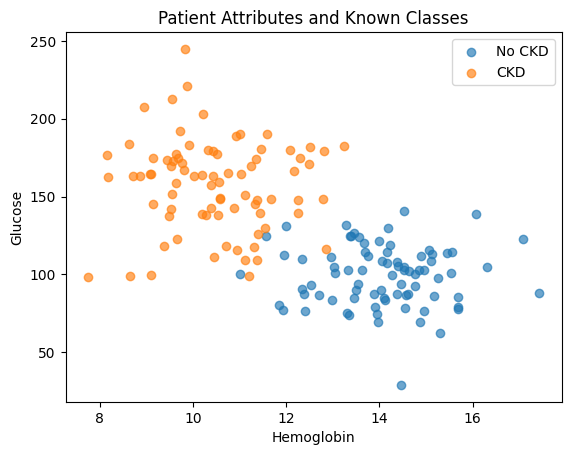

In [36]:
for label, name in [(0, "No CKD"), (1, "CKD")]:
    subset = patients[patients["Class"] == label]
    plt.scatter(
        subset["Hemoglobin"],
        subset["Glucose"],
        alpha=0.65,
        label=name
    )

plt.xlabel("Hemoglobin")
plt.ylabel("Glucose")
plt.title("Patient Attributes and Known Classes")
plt.legend()
plt.show()

# Part 5 — Euclidean Distance

Nearest-neighbor classification requires us to determine which observations are most similar.

For two attributes:


D = sqrt{(x_1-y_1)^2+(x_2-y_2)^2}


A **smaller distance** means the observations are more similar according to the selected attributes.

In [37]:
def distance(point1, point2):
    return np.sqrt(np.sum((point1 - point2)**2))

student_A = np.array([2, 3])
new_student = np.array([4, 5])

print("Distance:", distance(student_A, new_student))

Distance: 2.8284271247461903


### Activity — Calculate Distance

A new student has:

- Study Hours = 4
- Practice Problems = 5

Three training observations are:

- A = (2, 3)
- B = (5, 5)
- C = (7, 8)

Calculate the distance from the new student to each observation. Which one is nearest?

In [38]:
new_student = np.array([4, 5])

A = np.array([2, 3])
B = np.array([5, 5])
C = np.array([7, 8])

# YOUR CODE HERE
print("Distance to A:", distance(A, new_student))
print("Distance to B:", distance(B, new_student))
print("Distance to C:", distance(C, new_student))

Distance to A: 2.8284271247461903
Distance to B: 1.0
Distance to C: 4.242640687119285


# Part 6 — Why Standardization Matters

Our patient attributes use different numerical scales.

For example:

- Hemoglobin might be around 10–15.
- Glucose might be around 50–200.
- WBC might be around 4–11.

A feature with a larger numerical range can dominate Euclidean distance.

We therefore convert attributes to **standard units**:

\[
z = rac{x-	ext{mean}}{	ext{standard deviation}}
\]

After standardization, each attribute has approximately:

- Mean = 0
- Standard deviation = 1

In [8]:
feature_columns = ["Hemoglobin", "Glucose", "WBC"]

means = patients[feature_columns].mean()
stds = patients[feature_columns].std(ddof=0)

patients_std = patients.copy()

patients_std[feature_columns] = (
    patients[feature_columns] - means
) / stds

patients_std.head()

,Hemoglobin,Glucose,WBC,Class
0,-1.677064,1.446017,1.232168,1
1,-1.035324,0.911770,-1.146263,1
2,-0.409776,0.511247,2.024354,1
3,0.235130,0.514435,1.392126,1
4,-0.946576,1.950986,1.122853,1


In [9]:
patients_std[feature_columns].agg(["mean", "std"])

,Hemoglobin,Glucose,WBC
mean,-4.440892e-16,-2.664535e-16,5.329071e-16
std,1.003140e+00,1.003140e+00,1.003140e+00


# Part 7 — 1-Nearest-Neighbor Classification

To classify a new observation:

1. Calculate its distance from every training observation.
2. Find the smallest distance.
3. Find the class of that nearest observation.
4. Assign the same class to the new observation.

In [10]:
X = patients_std[feature_columns].to_numpy()
y = patients_std["Class"].to_numpy()

# New patient represented in STANDARD UNITS
new_patient = np.array([-0.8, 1.0, 0.5])

distances = np.sqrt(np.sum((X - new_patient)**2, axis=1))

nearest_index = np.argmin(distances)

print("Nearest observation index:", nearest_index)
print("Distance:", distances[nearest_index])
print("Nearest observation's class:", y[nearest_index])

Nearest observation index: 38
Distance: 0.39691691131783874
Nearest observation's class: 1


### Interpretation

If the nearest observation has class:

- `1` → predict CKD
- `0` → predict No CKD

### Build a 1-NN Classifier

In [11]:
def classify_1nn(training_X, training_y, new_point):
    distances = np.sqrt(
        np.sum((training_X - new_point)**2, axis=1)
    )

    nearest_index = np.argmin(distances)

    return training_y[nearest_index]

prediction = classify_1nn(X, y, new_patient)

print("Predicted class:", prediction)

Predicted class: 1


# Part 8 — k-Nearest Neighbors

Instead of using only one neighbor, **k-NN** uses the \(k\) closest observations.

Steps:

1. Calculate distances.
2. Sort observations by distance.
3. Select the \(k\) nearest observations.
4. Count their classes.
5. Predict the majority class.

For example, if the 5 nearest neighbors are:

`CKD, No CKD, CKD, CKD, No CKD`

then:

- CKD = 3 votes
- No CKD = 2 votes

Prediction = **CKD**

In [12]:
def classify_knn(training_X, training_y, new_point, k=5):
    distances = np.sqrt(
        np.sum((training_X - new_point)**2, axis=1)
    )

    nearest_indices = np.argsort(distances)[:k]
    neighbor_classes = training_y[nearest_indices]

    counts = np.bincount(neighbor_classes)

    return counts.argmax()

for k in [1, 3, 5, 7]:
    prediction = classify_knn(X, y, new_patient, k=k)
    print(f"k = {k}: predicted class = {prediction}")

k = 1: predicted class = 1
k = 3: predicted class = 1
k = 5: predicted class = 1
k = 7: predicted class = 1


### Activity — Inspect the Five Nearest Neighbors

In [13]:
k = 5

distances = np.sqrt(
    np.sum((X - new_patient)**2, axis=1)
)

nearest_indices = np.argsort(distances)[:k]

neighbors = patients_std.iloc[nearest_indices].copy()
neighbors["Distance"] = distances[nearest_indices]

neighbors

,Hemoglobin,Glucose,WBC,Class,Distance
38,-0.870533,0.749364,0.799583,1,0.396917
14,-1.216545,1.269546,0.551278,1,0.498793
58,-0.775627,0.541629,0.761627,1,0.528343
28,-0.893974,1.345328,0.935060,1,0.563347
17,-1.255235,0.605763,0.496988,1,0.602221


### Questions

1. How many of the 5 neighbors are CKD?
2. How many are No CKD?
3. What class should the classifier predict?


# Part 9 — Visualizing the Nearest Neighbors

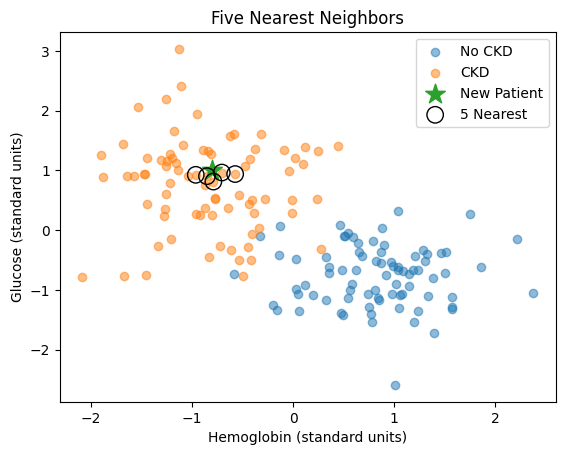

In [14]:
X_two = patients_std[["Hemoglobin", "Glucose"]].to_numpy()
new_two = new_patient[:2]

distances_two = np.sqrt(
    np.sum((X_two - new_two)**2, axis=1)
)

nearest_5 = np.argsort(distances_two)[:5]

for label, name in [(0, "No CKD"), (1, "CKD")]:
    mask = y == label
    plt.scatter(
        X_two[mask, 0],
        X_two[mask, 1],
        alpha=0.5,
        label=name
    )

plt.scatter(
    new_two[0],
    new_two[1],
    marker="*",
    s=220,
    label="New Patient"
)

plt.scatter(
    X_two[nearest_5, 0],
    X_two[nearest_5, 1],
    facecolors="none",
    edgecolors="black",
    s=140,
    label="5 Nearest"
)

plt.xlabel("Hemoglobin (standard units)")
plt.ylabel("Glucose (standard units)")
plt.title("Five Nearest Neighbors")
plt.legend()
plt.show()

# Part 10 — Training and Test Sets

We should not evaluate a classifier only on the observations used to build it.

Instead, we divide labeled data into:

- **Training set:** used by the classifier.
- **Test set:** held out for evaluation.


Here we will use approximately **70% training and 30% testing**.

In [15]:
indices = rng.permutation(len(patients_std))

train_size = int(0.70 * len(indices))

train_idx = indices[:train_size]
test_idx = indices[train_size:]

X_train = X[train_idx]
y_train = y[train_idx]

X_test = X[test_idx]
y_test = y[test_idx]

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Training observations: 112
Test observations: 48


### Why Not Test on the Training Data?

With 1-NN, each training observation is its own closest point.

This can make training accuracy look extremely high—even 100%.

That result can be misleading because our real goal is to classify **new observations**.

# Part 11 — Classify the Entire Test Set

In [16]:
def predict_all(training_X, training_y, test_X, k=5):
    predictions = []

    for point in test_X:
        prediction = classify_knn(
            training_X,
            training_y,
            point,
            k=k
        )
        predictions.append(prediction)

    return np.array(predictions)

test_predictions = predict_all(
    X_train,
    y_train,
    X_test,
    k=5
)

test_predictions[:10]

array([0, 0, 1, 0, 1, 0, 0, 0, 1, 0])

# Part 12 — Classification Accuracy

Accuracy
=
Number of Correct Predictions / Total Number of Predictions


In [17]:
correct = test_predictions == y_test

accuracy = np.mean(correct)

print("Correct predictions:", np.sum(correct))
print("Total predictions:", len(y_test))
print("Accuracy:", accuracy)
print("Accuracy (%):", round(accuracy * 100, 1))

Correct predictions: 47
Total predictions: 48
Accuracy: 0.9791666666666666
Accuracy (%): 97.9


### Interpretation

Write a sentence interpreting your test accuracy.

> Example structure: “The classifier correctly classified approximately ___% of the held-out test observations.”

# Part 13 — Training Accuracy vs. Test Accuracy

In [18]:
training_predictions = predict_all(
    X_train,
    y_train,
    X_train,
    k=1
)

test_predictions_k1 = predict_all(
    X_train,
    y_train,
    X_test,
    k=1
)

training_accuracy = np.mean(training_predictions == y_train)
test_accuracy_k1 = np.mean(test_predictions_k1 == y_test)

print("1-NN Training Accuracy:", training_accuracy)
print("1-NN Test Accuracy:", test_accuracy_k1)

1-NN Training Accuracy: 1.0
1-NN Test Accuracy: 0.9583333333333334


# Part 14 — False Positives and False Negatives

For this activity:

- **Positive class = CKD**
- **Negative class = No CKD**

Therefore:

- **True Positive (TP):** CKD patient correctly predicted as CKD.
- **True Negative (TN):** No-CKD patient correctly predicted as No CKD.
- **False Positive (FP):** No-CKD patient incorrectly predicted as CKD.
- **False Negative (FN):** CKD patient incorrectly predicted as No CKD.

In [19]:
pred = test_predictions

TP = np.sum((pred == 1) & (y_test == 1))
TN = np.sum((pred == 0) & (y_test == 0))
FP = np.sum((pred == 1) & (y_test == 0))
FN = np.sum((pred == 0) & (y_test == 1))

print("True Positives :", TP)
print("True Negatives :", TN)
print("False Positives:", FP)
print("False Negatives:", FN)

True Positives : 24
True Negatives : 23
False Positives: 1
False Negatives: 0


### Build a Simple Confusion Matrix

In [20]:
confusion = pd.DataFrame(
    {
        "Actual CKD": [TP, FN],
        "Actual No CKD": [FP, TN]
    },
    index=["Predicted CKD", "Predicted No CKD"]
)

confusion

,Actual CKD,Actual No CKD
Predicted CKD,24,1
Predicted No CKD,0,23


### Discussion

1. Which error represents a patient who actually has CKD but is predicted as No CKD?
2. Which error represents a patient without CKD who is predicted as CKD?
3. Why might the two errors have different consequences in a real application?
4. Why can overall accuracy hide important information about errors?

# Part 15 — Choosing k

The value of \(k\) affects classifier behavior.

- Very small \(k\): sensitive to individual observations and noise.
- Moderate \(k\): uses a broader neighborhood.
- Very large \(k\): can ignore useful local patterns.

Let's compare several odd values of \(k\).

In [21]:
k_values = list(range(1, 22, 2))
accuracies = []

for k in k_values:
    predictions = predict_all(
        X_train,
        y_train,
        X_test,
        k=k
    )

    accuracies.append(
        np.mean(predictions == y_test)
    )

results = pd.DataFrame({
    "k": k_values,
    "Test Accuracy": accuracies
})

results

,k,Test Accuracy
0,1,0.958333
1,3,0.979167
2,5,0.979167
3,7,1.000000
4,9,1.000000
5,11,0.979167
6,13,0.958333
7,15,0.958333
8,17,0.958333
9,19,0.979167


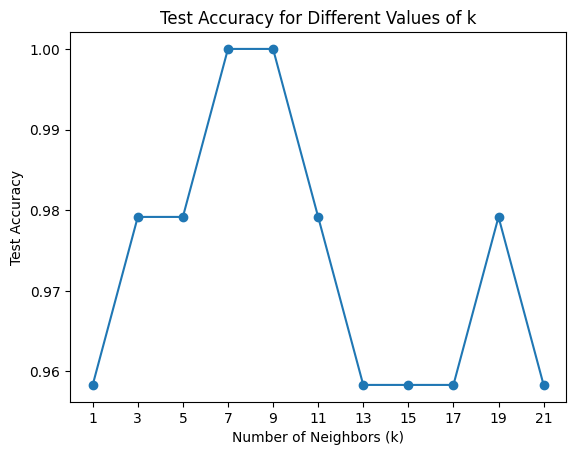

In [22]:
plt.plot(
    k_values,
    accuracies,
    marker="o"
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy for Different Values of k")
plt.xticks(k_values)
plt.show()

### Activity — Interpret the Graph

1. Which value of \(k\) produced the highest accuracy in this split?
2. Did accuracy remain constant as \(k\) increased?


# Part 16 — Multiple Attributes and Dimensions

k-NN is not limited to two attributes.

- 2 attributes → points in 2D
- 3 attributes → points in 3D
- 4+ attributes → higher-dimensional space

We may not be able to draw higher-dimensional space easily, but the distance calculation still works.

### Compare Two Attributes vs. Three Attributes

In [23]:
# Two attributes
X2 = patients_std[["Hemoglobin", "Glucose"]].to_numpy()

# Three attributes
X3 = patients_std[["Hemoglobin", "Glucose", "WBC"]].to_numpy()

X2_train = X2[train_idx]
X2_test = X2[test_idx]

X3_train = X3[train_idx]
X3_test = X3[test_idx]

pred_2 = predict_all(
    X2_train, y_train, X2_test, k=5
)

pred_3 = predict_all(
    X3_train, y_train, X3_test, k=5
)

accuracy_2 = np.mean(pred_2 == y_test)
accuracy_3 = np.mean(pred_3 == y_test)

print("Accuracy using 2 attributes:", accuracy_2)
print("Accuracy using 3 attributes:", accuracy_3)

Accuracy using 2 attributes: 0.9791666666666666
Accuracy using 3 attributes: 0.9791666666666666


### Discussion

1. Did adding the third attribute improve accuracy in this particular example?


# Part 17 — Classify Your Own New Patient

Enter values in **standard units** and compare predictions for different values of \(k\).

In [24]:
your_patient = np.array([
    -0.5,   # Hemoglobin
     0.8,   # Glucose
     0.3    # WBC
])

for k in [1, 3, 5, 7, 9]:
    prediction = classify_knn(
        X_train,
        y_train,
        your_patient,
        k=k
    )

    label = "CKD" if prediction == 1 else "No CKD"

    print(f"k={k}: {label}")

k=1: CKD
k=3: CKD
k=5: CKD
k=7: CKD
k=9: CKD


# Part 18 — Introduction to Logistic Regression

So far, we have used **k-nearest neighbors (k-NN)** to classify patients.

Another widely used method for **binary classification** is **logistic regression**.

Despite the word *regression* in its name, logistic regression can be used to predict a **categorical class** such as:

- CKD / No CKD
- Spam / Not Spam
- Fraud / Not Fraud
- Malignant / Benign

A useful way to think about logistic regression is:

> **Features → predicted probability → class prediction**

For example, instead of immediately saying that a patient has CKD, the model might first estimate:

**P(CKD) = ?**

We can then use a **classification threshold** to convert that probability into a class.

## The 0.50 Classification Threshold

A common starting threshold is **0.50**.

- If (P(CKD) > = 0.50) → predict **CKD**
- If (P(CKD) < 0.50) → predict **No CKD**

Example:

| Patient | Predicted P(CKD) | Predicted Class |
|---|---:|---|
| A | 0.18 | No CKD |
| B | 0.43 | No CKD |
| C | 0.67 | CKD |
| D | 0.91 | CKD |

The important idea is that logistic regression gives us both a **probability** and, after applying a threshold, a **class prediction**.

## Install/Import the Logistic Regression Model

We will use `LogisticRegression` from **scikit-learn**.

We will keep the **same training and test sets** that we used for k-NN so that the comparison is fair.

In [39]:
from sklearn.linear_model import LogisticRegression

## Step 1 — Build the Logistic Regression Classifier

We already created:

- `X_train` — training features
- `y_train` — known training classes
- `X_test` — test features
- `y_test` — known test classes

Now we create the classifier and fit it using the training observations.

In [40]:
logistic_model = LogisticRegression()

logistic_model.fit(X_train, y_train)

print("Logistic regression classifier has been trained.")

Logistic regression classifier has been trained.


## Step 2 — Predict Probabilities

Instead of looking at the final classes first, let's examine the probabilities.

`predict_proba()` returns two probabilities for each observation:

1. Probability of class `0` → No CKD
2. Probability of class `1` → CKD

The two probabilities for each patient add up to approximately 1.

In [41]:
probabilities = logistic_model.predict_proba(X_test)

probability_table = pd.DataFrame({
    "P(No CKD)": probabilities[:, 0],
    "P(CKD)": probabilities[:, 1],
    "True Class": y_test
})

probability_table.head(10)

,P(No CKD),P(CKD),True Class
0,0.953508,0.046492,0
1,0.932592,0.067408,0
2,0.009369,0.990631,1
3,0.989256,0.010744,0
4,0.000139,0.999861,1
5,0.993256,0.006744,0
6,0.990062,0.009938,0
7,0.997208,0.002792,0
8,0.002660,0.997340,1
9,0.907814,0.092186,0


### Activity — Interpret the Probabilities

Look at the first few test patients.

For each patient:

1. Which class has the larger predicted probability?
2. Is P(CKD) above or below 0.50?
3. What class would you predict?
4. Does the prediction agree with the true class?

# Part 19 — Convert Probabilities into Classes

Let's apply a threshold of **0.50** ourselves.

In [28]:
ckd_probabilities = probabilities[:, 1]

manual_predictions = (ckd_probabilities >= 0.50).astype(int)

results_logistic = pd.DataFrame({
    "P(CKD)": ckd_probabilities,
    "Predicted Class": manual_predictions,
    "True Class": y_test
})

results_logistic.head(10)

,P(CKD),Predicted Class,True Class
0,0.046492,0,0
1,0.067408,0,0
2,0.990631,1,1
3,0.010744,0,0
4,0.999861,1,1
5,0.006744,0,0
6,0.009938,0,0
7,0.002792,0,0
8,0.997340,1,1
9,0.092186,0,0


The model's built-in `predict()` method performs this classification step for us.

In [29]:
logistic_predictions = logistic_model.predict(X_test)

print("First 10 predictions:")
print(logistic_predictions[:10])

First 10 predictions:
[0 0 1 0 1 0 0 0 1 0]


# Part 20 — Evaluate Logistic Regression Accuracy

In [30]:
logistic_accuracy = np.mean(logistic_predictions == y_test)

print("Correct predictions:",
      np.sum(logistic_predictions == y_test))

print("Total test observations:",
      len(y_test))

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 1), "%")

Correct predictions: 47
Total test observations: 48
Logistic Regression Accuracy: 97.9 %


### Interpretation

Complete the sentence:

> Using the held-out test set, logistic regression correctly classified approximately **_____ %** of the patients.

# Part 21 — Logistic Regression Confusion Matrix

As with k-NN, overall accuracy does not tell us what kinds of mistakes were made.

Let's count:

- True Positives
- True Negatives
- False Positives
- False Negatives

In [31]:
pred = logistic_predictions

TP_log = np.sum((pred == 1) & (y_test == 1))
TN_log = np.sum((pred == 0) & (y_test == 0))
FP_log = np.sum((pred == 1) & (y_test == 0))
FN_log = np.sum((pred == 0) & (y_test == 1))

logistic_confusion = pd.DataFrame(
    {
        "Actual CKD": [TP_log, FN_log],
        "Actual No CKD": [FP_log, TN_log]
    },
    index=["Predicted CKD", "Predicted No CKD"]
)

logistic_confusion

,Actual CKD,Actual No CKD
Predicted CKD,24,1
Predicted No CKD,0,23


# Part 22 — Visualize Predicted CKD Probabilities

The graph below shows the predicted probability of CKD for each test observation.

The horizontal line represents the **0.50 classification threshold**.

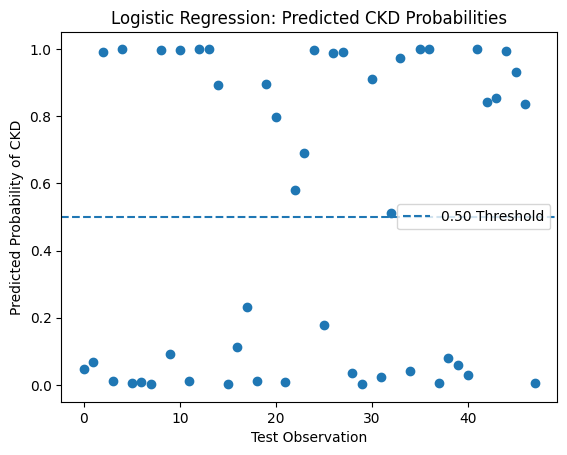

In [32]:
plt.scatter(
    np.arange(len(ckd_probabilities)),
    ckd_probabilities
)

plt.axhline(
    0.50,
    linestyle="--",
    label="0.50 Threshold"
)

plt.xlabel("Test Observation")
plt.ylabel("Predicted Probability of CKD")
plt.title("Logistic Regression: Predicted CKD Probabilities")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.show()

### Reading the Graph

- Points **above 0.50** are predicted as CKD.
- Points **below 0.50** are predicted as No CKD.
- A probability near 0.50 represents a less clear-cut classification than a probability near 0 or 1.

# Part 23 — What Happens If We Change the Threshold?

The threshold does **not** have to be 0.50.

Let's compare several thresholds.

In [33]:
for threshold in [0.30, 0.50, 0.70]:

    predictions_at_threshold = (
        ckd_probabilities >= threshold
    ).astype(int)

    accuracy_at_threshold = np.mean(
        predictions_at_threshold == y_test
    )

    false_negatives = np.sum(
        (predictions_at_threshold == 0) &
        (y_test == 1)
    )

    false_positives = np.sum(
        (predictions_at_threshold == 1) &
        (y_test == 0)
    )

    print(
        f"Threshold = {threshold:.2f} | "
        f"Accuracy = {accuracy_at_threshold:.3f} | "
        f"FP = {false_positives} | "
        f"FN = {false_negatives}"
    )

Threshold = 0.30 | Accuracy = 0.979 | FP = 1 | FN = 0
Threshold = 0.50 | Accuracy = 0.979 | FP = 1 | FN = 0
Threshold = 0.70 | Accuracy = 0.958 | FP = 0 | FN = 2


# Part 24 — Compare k-NN and Logistic Regression

Both methods solve the same binary classification problem, but they make predictions differently.

| k-NN | Logistic Regression |
|---|---|
| Finds nearby training observations | Estimates class probability |
| Uses majority vote | Applies a probability threshold |
| Prediction depends on local neighbors | Prediction comes from a fitted probability model |
| Produces a predicted class | Produces probability + predicted class |

Let's compare their test accuracy on the same data.

In [34]:
knn_predictions = predict_all(
    X_train,
    y_train,
    X_test,
    k=5
)

knn_accuracy = np.mean(
    knn_predictions == y_test
)

comparison = pd.DataFrame({
    "Classifier": [
        "5-Nearest Neighbors",
        "Logistic Regression"
    ],
    "Test Accuracy": [
        knn_accuracy,
        logistic_accuracy
    ]
})

comparison

,Classifier,Test Accuracy
0,5-Nearest Neighbors,0.979167
1,Logistic Regression,0.979167


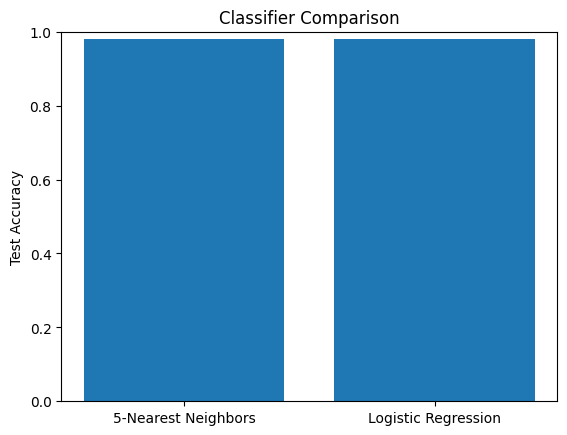

In [35]:
plt.bar(
    comparison["Classifier"],
    comparison["Test Accuracy"]
)

plt.ylabel("Test Accuracy")
plt.title("Classifier Comparison")
plt.ylim(0, 1)
plt.show()